# BSISO1 phase composites: Ekman transport, MSE and Ekman advection

Composites by BSISO1 phase (active days, amplitude > 1) from `bsiso_phase.jl`, file `ekman_bsiso1_phase_2012-2020.nc`. The first figures show one phase `p`, as in `ekman_plots.ipynb` for a pentad; the last two show zonal wind stress and surface-air MSE for all 8 phases, to pick out the phases of interest (e.g. monsoon onset). The library `ekman_V_ma_mo_plot.jl` is loaded with Revise `includet`.

Kernel: "Julia", started with `--project=@.`, which finds `plot/Project.toml`.

In [1]:
using Revise
using Statistics
includet("ekman_V_ma_mo_plot.jl")

    CondaPkg Found dependencies: /home/ceoas/deszoeks/.julia/packages/CondaPkg/Pc7ZA/CondaPkg.toml
    CondaPkg Found dependencies: /home/ceoas/deszoeks/.julia/packages/PythonCall/trYos/CondaPkg.toml
    CondaPkg Found dependencies: /home/ceoas/deszoeks/.julia/packages/PythonPlot/96RVm/CondaPkg.toml
    CondaPkg Initialising pixi
             │ /home/ceoas/deszoeks/.julia/artifacts/8429d049f6c01106c62971e9540e146dc068df25/bin/pixi
             │ init
             │ --format pixi
             └ /ceoas/deszoeks/projects/ekman-astz/plot/.CondaPkg
Created /ceoas/deszoeks/projects/ekman-astz/plot/.CondaPkg/pixi.toml
    CondaPkg Wrote /ceoas/deszoeks/projects/ekman-astz/plot/.CondaPkg/pixi.toml
             │ [dependencies]
             │ matplotlib = ">=1"
             │ openssl = ">=3, <3.6"
             │ 
             │     [dependencies.python]
             │     version = ">=3.10,!=3.14.0,!=3.14.1,<4"
             │     build = "*cp*"
             │     channel = "conda-forge"
       

"K kg m\$^{-2}\$ s\$^{-1}\$"

## Data
Phase `p` in the region `lonlim`, `latlim`; only that region is read. `d`: composite fields as read; `f`: the fields plotted. `ndays`: the number of active days composited in a phase (the maximum of `nobs_taux` over the region). `Ro_rad` curtails M near the equator after compositing (see `ekman_fields`).

In [2]:
file = "../ekman_bsiso1_phase_2012-2020.nc"
p = 4                                # BSISO1 phase (1-8)
lonlim, latlim = (40, 110), (-5, 30) # degrees: Indian Ocean; only this region is read
ylims = (0, 25)                      # degrees latitude shown on the maps (axis limits)
Ro_rad = 250e3 # m, curtail M by r = 1 - exp(-y^2/Ro_rad^2) near the equator (plotting only)
advlim = 180   # W m^-2, color limit for the enthalpy advection panels
phases = NCDataset(nc -> nc["phase"][:], file) # 1:8
ndays(k) = Int(maximum(read_group(file, k; vars=("nobs_taux",), lonlim, latlim).nobs_taux))
k = findfirst(==(p), phases)
d = read_group(file, k; lonlim, latlim)
f = ekman_fields(d; Ro_rad)
figtitle = "$(basename(file)): BSISO1 phase $p, $(ndays(k)) days (Ro_rad = $(Ro_rad/1e3) km)"
size(f.Mx), keys(f)

((281, 141), (:lon, :lat, :Mx, :My, :m_a, :m_o, :dmodx, :dmody, :dmadx, :dmady, :advT_o, :advT_a, :adv_o, :adv_a, :sdiv_o, :sdiv_a, :flux_o, :flux_a, :r, :land))

## Ekman transport, surface-air MSE and ocean-surface enthalpy, phase `p`
Each figure is a list of `panel(x, title, units; cmap="RdBu_r", kw...)`, filled in row by row (2 columns). `kw` go to `pcolormesh`; without vmin/vmax the limits are ±98th percentile of |x|. The MSE limits are copied from the pentad notebook; adjust them for the phase.

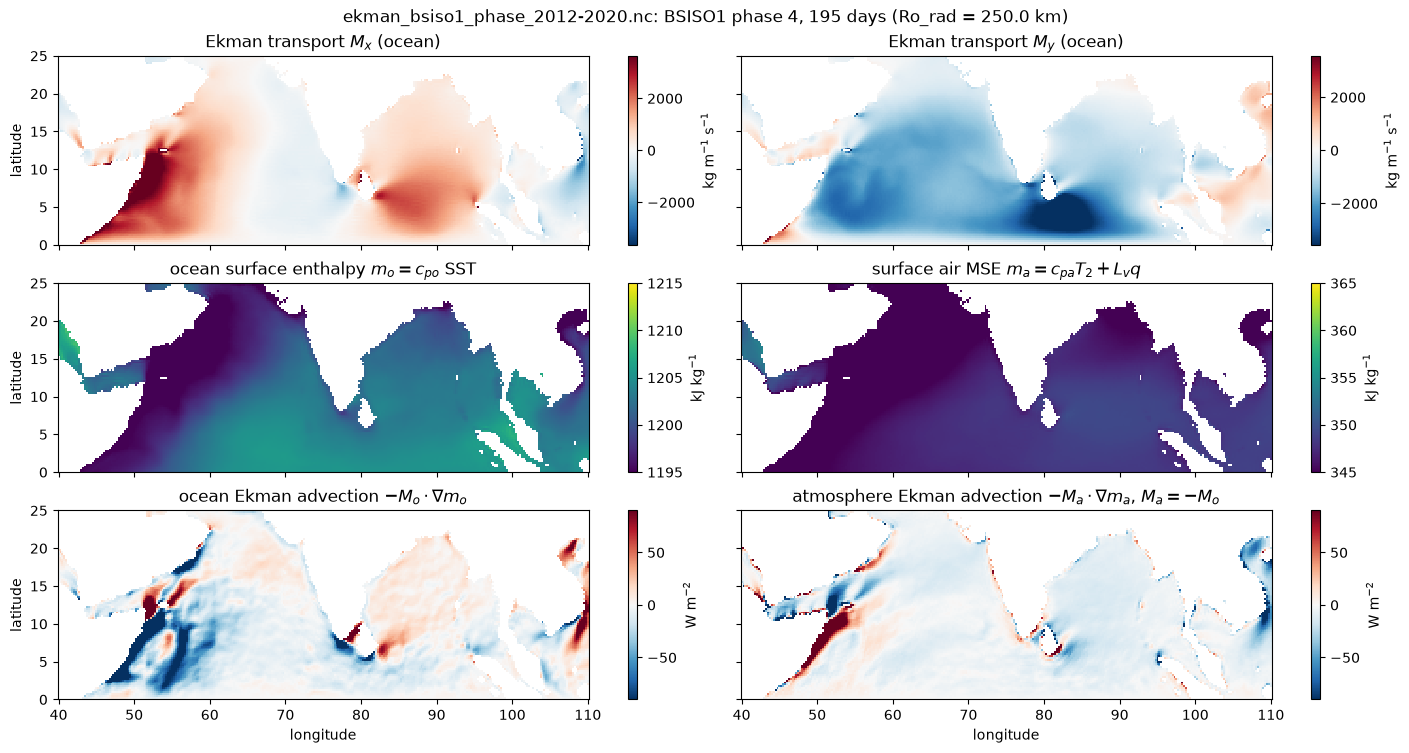

In [17]:
panels1 = [
    panel(f.Mx, raw"Ekman transport $M_x$ (ocean)", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.My, raw"Ekman transport $M_y$ (ocean)", raw"kg m$^{-1}$ s$^{-1}$"),
    panel(f.m_o ./ 1e3, raw"ocean surface enthalpy $m_o = c_{po}$ SST", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=1195, vmax=1215),
    panel(f.m_a ./ 1e3, raw"surface air MSE $m_a = c_{pa} T_2 + L_v q$", raw"kJ kg$^{-1}$"; cmap="viridis", vmin=345, vmax=365),
    panel(f.adv_o, raw"ocean Ekman advection $-M_o \cdot \nabla m_o$", flux_units; vmin=-advlim/2, vmax=advlim/2),
    panel(f.adv_a, raw"atmosphere Ekman advection $-M_a \cdot \nabla m_a$, $M_a = -M_o$", flux_units; vmin=-advlim/2, vmax=advlim/2)
    ]    
fig1, axs1 = plot_panels(f.lon, f.lat, panels1; land=f.land, suptitle=figtitle);
for ax in axs1.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig1.savefig("bsiso_V_ma_mo_phase$p.png")

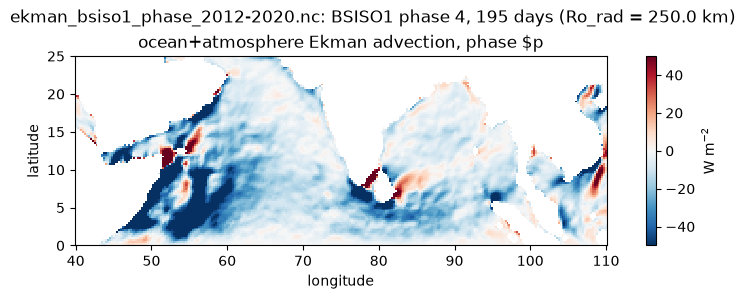

In [22]:
panel_tot_adv = [
    panel(f.adv_o.+f.adv_a, raw"ocean+atmosphere Ekman advection, phase $p", 
        flux_units, vmin=-50, vmax=50)
    ]
fig_tot, axs_tot = plot_panels(f.lon, f.lat, panel_tot_adv; ncols=1, land=f.land, suptitle=figtitle);
for ax in axs_tot.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end

## Ocean and atmosphere Ekman advection and their sum, phase `p`
Columns: ocean, atmosphere, sum. Rows: temperature (mass-weighted, K kg m$^{-2}$ s$^{-1}$) and (moist) enthalpy, W m$^{-2}$. Each row shares its color limits.

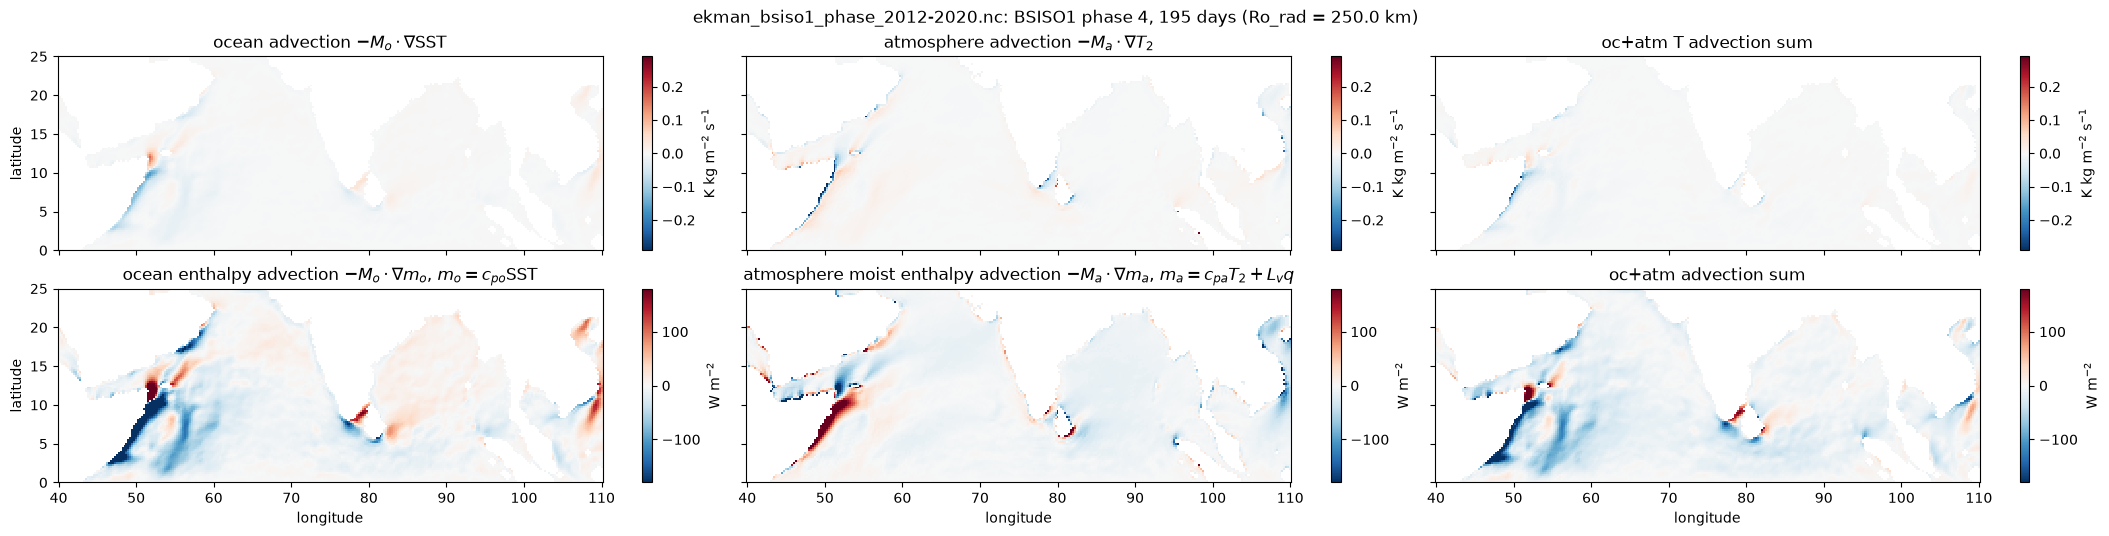

In [12]:
Tlim = maximum(symlim, (f.advT_o, f.advT_a)) # shared by the temperature row
Hlim = advlim                                # W m^-2, shared by the enthalpy row
panels_adv = [
    panel(f.advT_o, raw"ocean advection $-M_o \cdot \nabla$SST", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.advT_a, raw"atmosphere advection $-M_a \cdot \nabla T_2$", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.advT_o .+ f.advT_a, "oc+atm T advection sum", advT_units; vmin=-Tlim, vmax=Tlim),
    panel(f.adv_o, raw"ocean enthalpy advection $-M_o \cdot \nabla m_o$, $m_o = c_{po}$SST", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.adv_a, raw"atmosphere moist enthalpy advection $-M_a \cdot \nabla m_a$, $m_a = c_{pa}T_2 + L_v q$", flux_units; vmin=-Hlim, vmax=Hlim),
    panel(f.adv_o .+ f.adv_a, "oc+atm advection sum", flux_units; vmin=-Hlim, vmax=Hlim)]
fig_adv, axs_adv = plot_panels(f.lon, f.lat, panels_adv; ncols=3, land=f.land, suptitle=figtitle);
for ax in axs_adv.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_adv.savefig("bsiso_adv_sum_phase$p.png")

## All 8 phases: zonal wind stress and surface-air MSE
Read all 8 phases at once, only what these maps need (`taux`, `sst` for the land mask, `t2`, `q`, `nobs_taux`); each variable is lon x lat x phase, indexed `dp[:taux][i, j, q]` (`dp.lon[i]`, `dp.lat[j]`, phase `q`). `anom(x; dims=3)` is x minus its mean over the 8 phases (dimension 3), e.g. `anom(dp.taux; dims=3)`. All 8 panels of a figure share one color scale; the panel titles give the number of active days in each phase.

In [6]:
dp = read_group(file, 1:8; vars=("taux", "sst", "t2", "q", "nobs_taux"), lonlim, latlim) # each lon x lat x phase
@assert dp.dimval == 1:8 # index q along the third dimension is phase q
dp = merge(dp, (; ma = @. (c_pa*dp.t2 + Lv*dp.q) / 1e3)) # surface-air MSE m_a = c_pa T_2 + L_v q, kJ/kg
# anomalies
anom(x; dims=1) = x .- mean(x; dims=dims)

anom (generic function with 1 method)

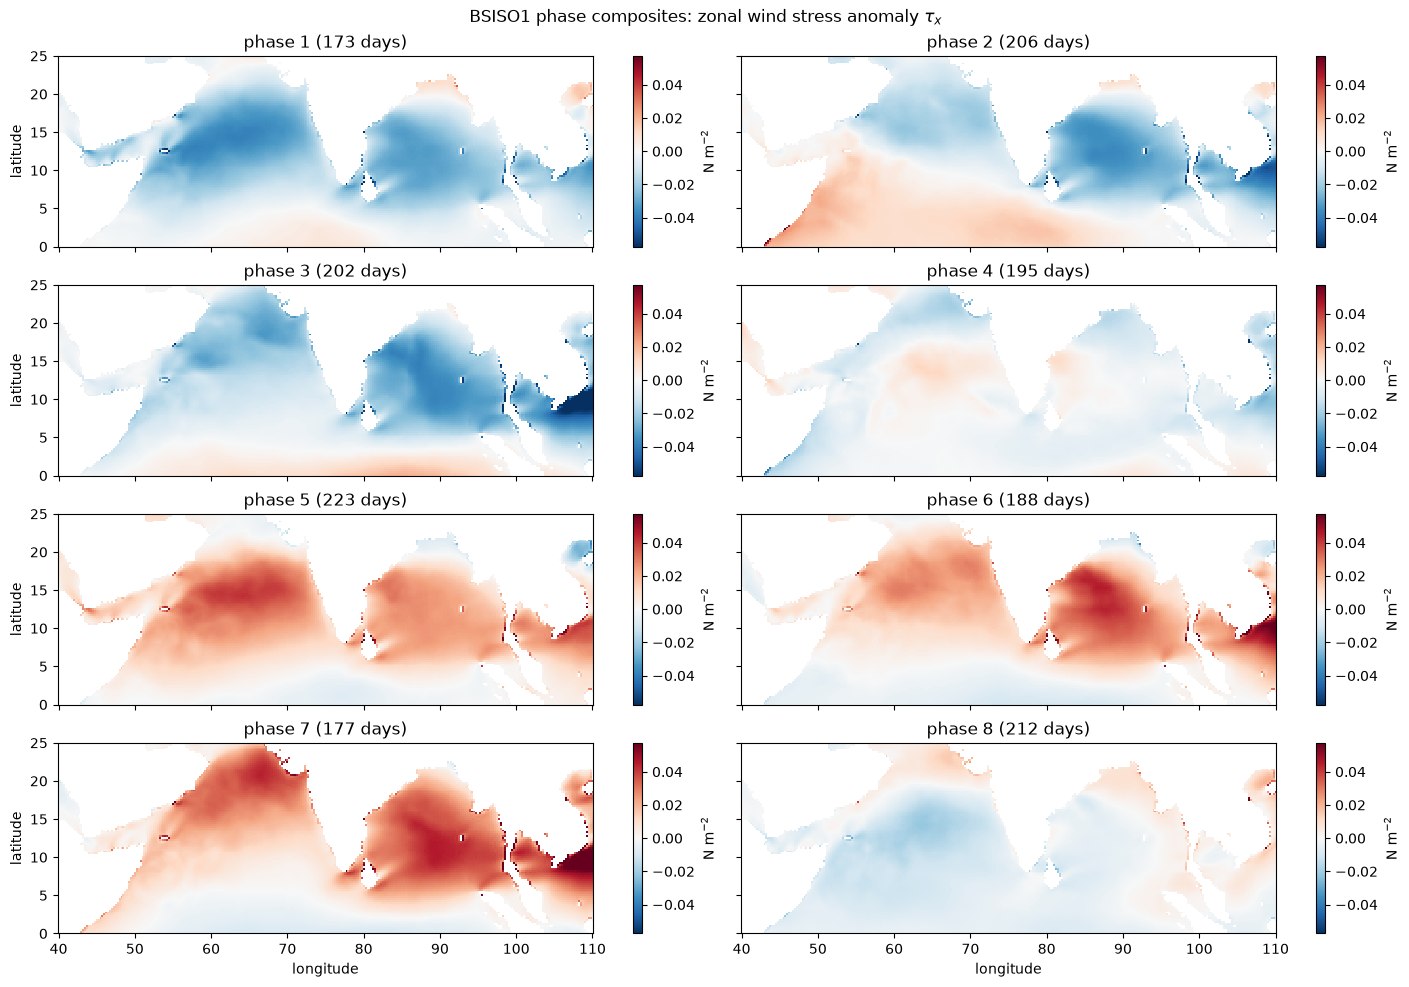

In [14]:
lon, lat, land = dp.lon, dp.lat, isnan.(dp.sst[:, :, 1])
daytitle(q) = "phase $q ($(Int(maximum(dp.nobs_taux[:, :, q]))) days)"
taulim = maximum(q -> symlim(anom(dp.taux; dims=3)[:, :, q]), 1:8)/2 # N m^-2, shared by all phases
panels_tau = [panel(anom(dp.taux; dims=3)[:, :, q], daytitle(q), raw"N m$^{-2}$"; vmin=-taulim, vmax=taulim) for q in 1:8]
fig_tau, axs_tau = plot_panels(lon, lat, panels_tau; 
    ncols=2, land, suptitle=raw"BSISO1 phase composites: zonal wind stress anomaly $\tau_x$");
for ax in axs_tau.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_tau.savefig("bsiso_taux_phases.png")

BSISO progress of surface MSE is surprisingly nonmonotonic.

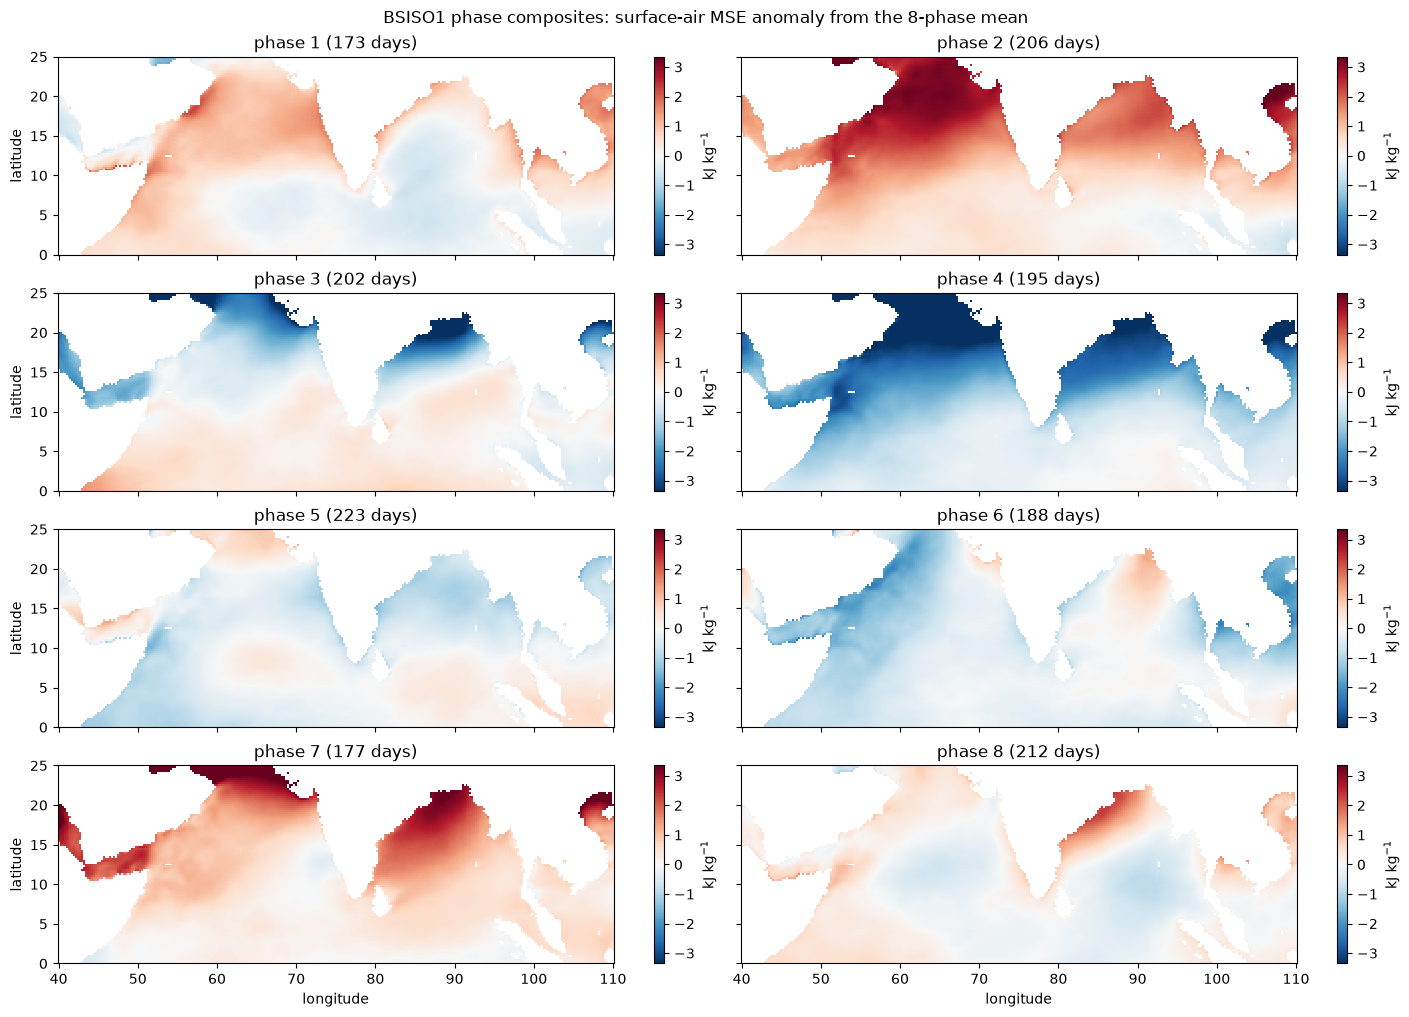

In [15]:
ma_anom = anom(dp.ma, dims=3) # kJ/kg, phase minus 8-phase mean
alim = symlim(ma_anom[.!land, :])
panels_ma_anom = [panel(ma_anom[:, :, q], daytitle(q), raw"kJ kg$^{-1}$"; vmin=-alim, vmax=alim) for q in 1:8]
fig_ma_anom, axs_ma_anom = plot_panels(lon, lat, panels_ma_anom; ncols=2, land, suptitle=raw"BSISO1 phase composites: surface-air MSE anomaly from the 8-phase mean");
for ax in axs_ma_anom.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_ma_anom.savefig("bsiso_ma_anom_phases.png")

## All 8 phases: ocean, atmosphere and total Ekman advection of (moist) enthalpy
`fp`: `ekman_fields` of all 8 phases at once, each field lon x lat x phase, e.g. `fp.adv_o[:, :, q]` (curtailed with `Ro_rad`). Ocean $-M_o \cdot \nabla m_o$, atmosphere $-M_a \cdot \nabla m_a$, and their sum, W m$^{-2}$; color limits ±`advlim/2` for ocean and atmosphere, ±50 for the total, as for phase `p`.

In [23]:
fp = ekman_fields(read_group(file, 1:8; lonlim, latlim); Ro_rad) # each field lon x lat x phase
size(fp.adv_o)

(281, 141, 8)

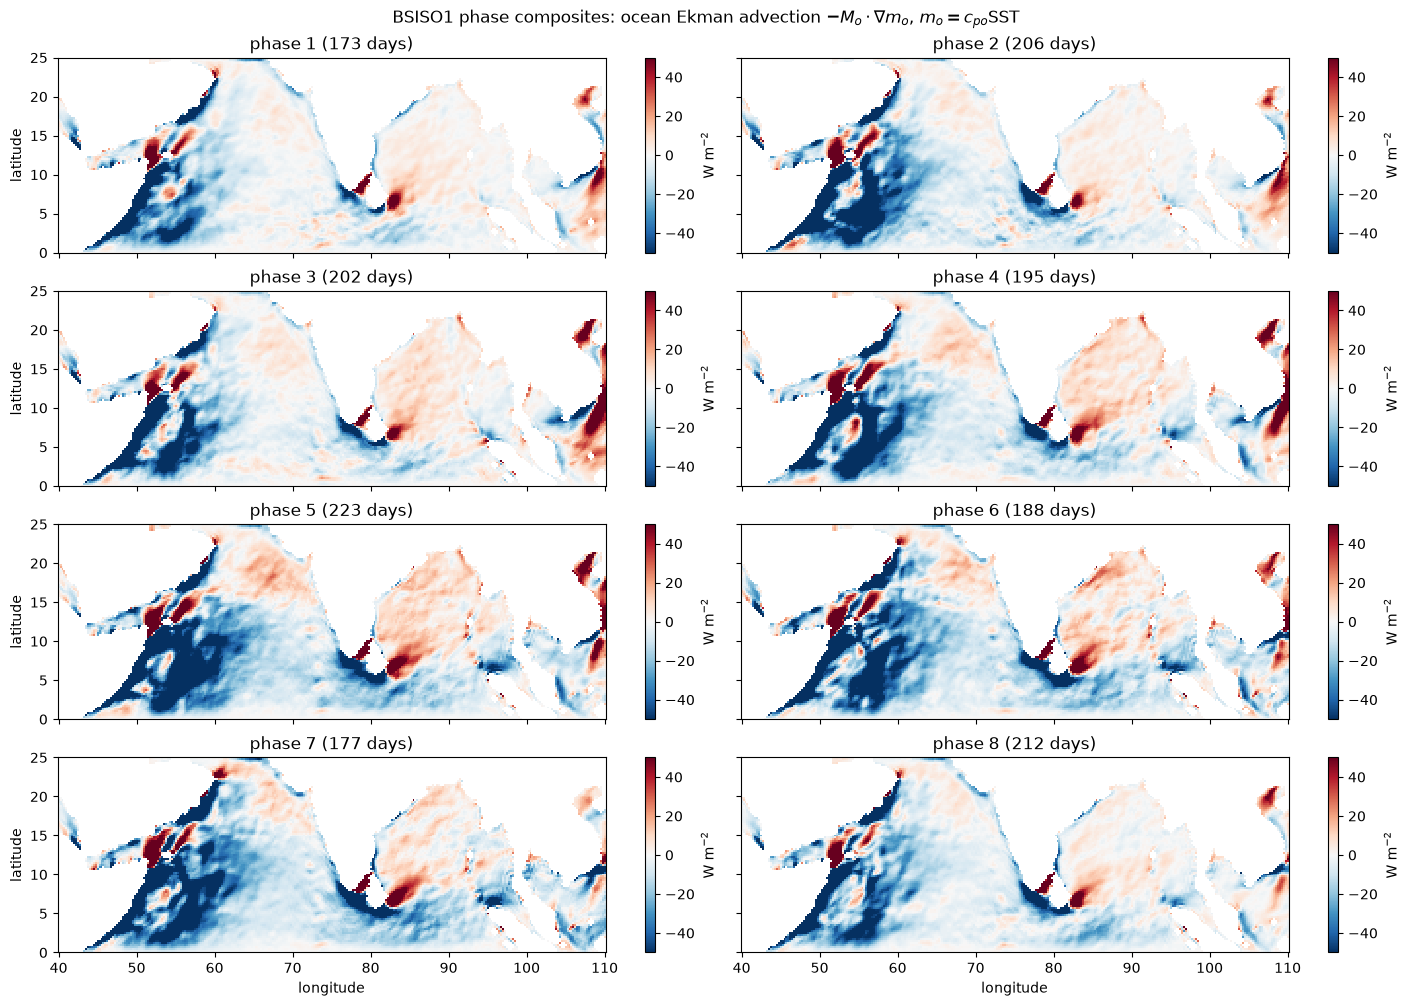

In [27]:
panels_adv_o = [panel(fp.adv_o[:, :, q], daytitle(q), flux_units; vmin=-50, vmax=50) for q in 1:8]
fig_adv_o, axs_adv_o = plot_panels(lon, lat, panels_adv_o; ncols=2, land,
    suptitle=raw"BSISO1 phase composites: ocean Ekman advection $-M_o \cdot \nabla m_o$, $m_o = c_{po}$SST");
for ax in axs_adv_o.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_adv_o.savefig("bsiso_adv_o_phases.png")

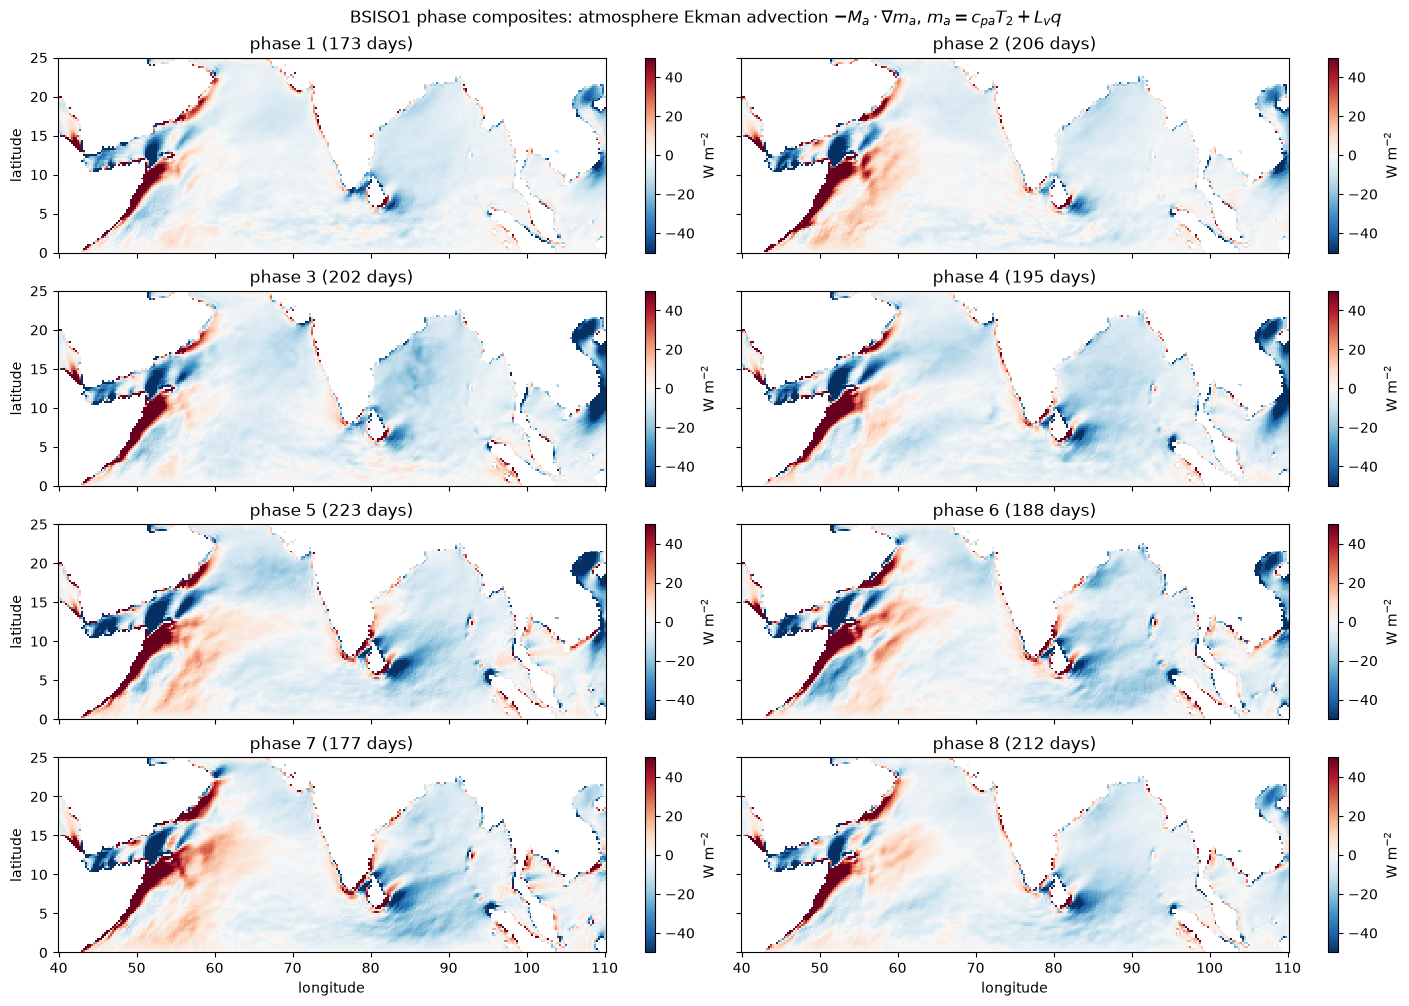

In [28]:
panels_adv_a = [panel(fp.adv_a[:, :, q], daytitle(q), flux_units; vmin=-50, vmax=50) for q in 1:8]
fig_adv_a, axs_adv_a = plot_panels(lon, lat, panels_adv_a; ncols=2, land,
    suptitle=raw"BSISO1 phase composites: atmosphere Ekman advection $-M_a \cdot \nabla m_a$, $m_a = c_{pa}T_2 + L_v q$");
for ax in axs_adv_a.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_adv_a.savefig("bsiso_adv_a_phases.png")

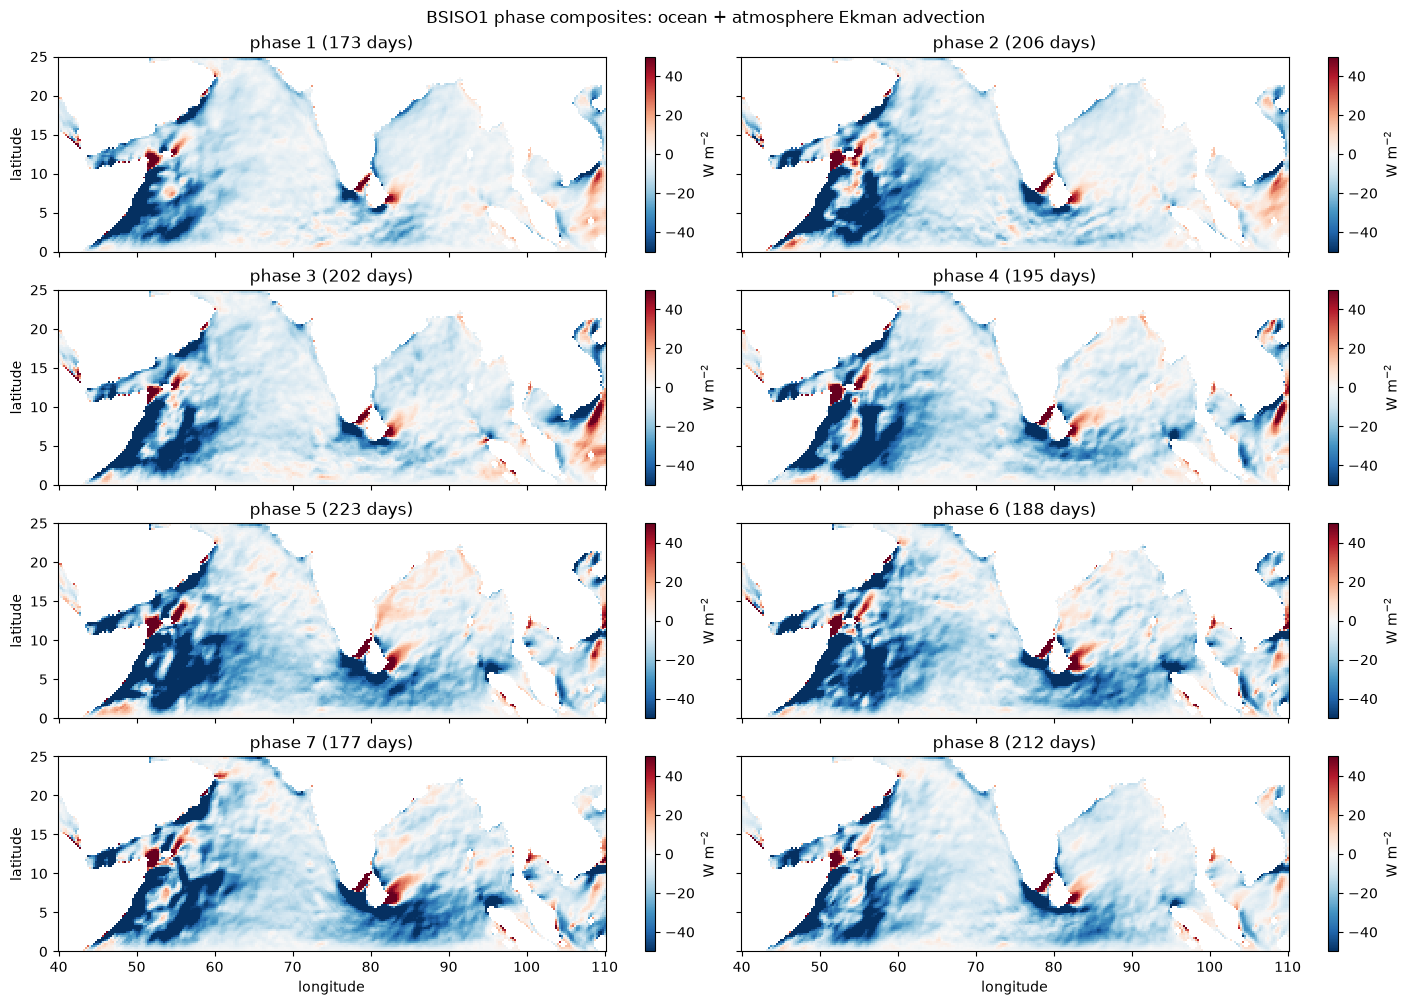

In [26]:
panels_adv_tot = [panel(fp.adv_o[:, :, q] .+ fp.adv_a[:, :, q], daytitle(q), flux_units; vmin=-50, vmax=50) for q in 1:8]
fig_adv_tot, axs_adv_tot = plot_panels(lon, lat, panels_adv_tot; ncols=2, land,
    suptitle="BSISO1 phase composites: ocean + atmosphere Ekman advection");
for ax in axs_adv_tot.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_adv_tot.savefig("bsiso_adv_tot_phases.png")

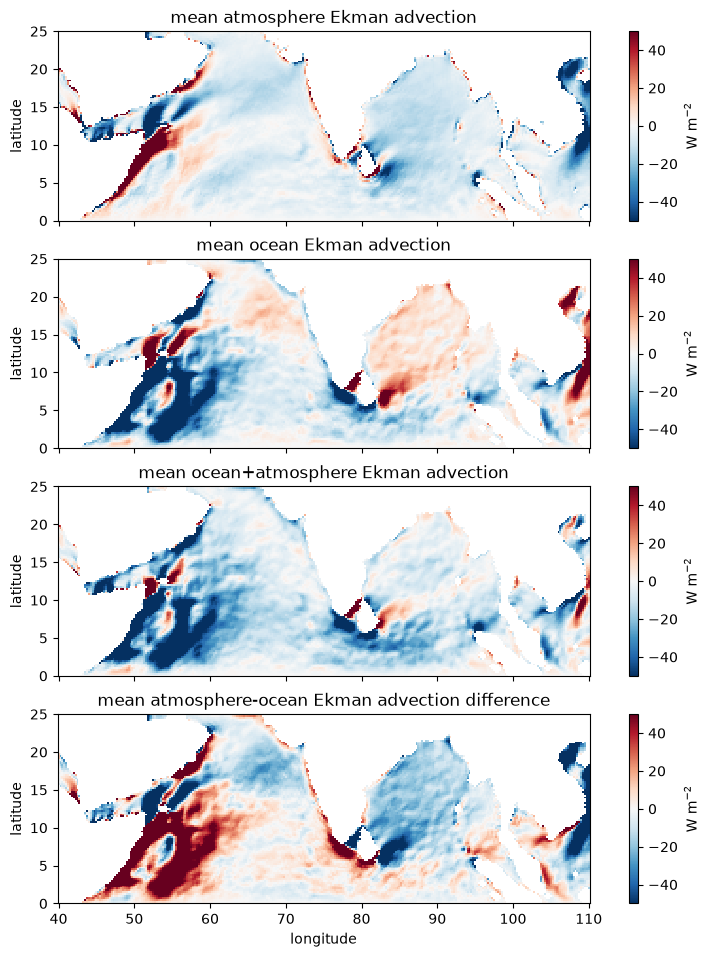

In [39]:
panel_mn_adv = [
    panel(mean(f.adv_a; dims=3), raw"mean atmosphere Ekman advection", 
        flux_units, vmin=-50, vmax=50)
    panel(mean(f.adv_o; dims=3), raw"mean ocean Ekman advection", 
        flux_units, vmin=-50, vmax=50)
    panel(mean(f.adv_o.+f.adv_a; dims=3), raw"mean ocean+atmosphere Ekman advection", 
        flux_units, vmin=-50, vmax=50)
    panel(mean(f.adv_a.-f.adv_o; dims=3), raw"mean atmosphere-ocean Ekman advection difference", 
        flux_units, vmin=-50, vmax=50)
    ]
fig_mn, axs_mn = plot_panels(f.lon, f.lat, panel_mn_adv; ncols=1, land=f.land, suptitle="");
for ax in axs_mn.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end

Net atmosphere+ocean is cooling most phases, most places. This is because
frictional atmospheric wind slides from high to low pressure. For hydrostatic surface pressure, this is from high to low density, from low to high T and MSE. This makes atmospheric Ekman advection tend to be negative, bringing cool wind from high pressure anticyclones to the warm pools where there is deep convection.

This isn't true of the Ekman flux in the ocean, because ocean temperature and pressure are largely independent of wind stress. 
Strong cold advection in the ocean *is* driven by Ekman pumping of cold upwelled water. This is the same sign as the atmospheric cold advection, but for quite a different reason--the temperature gradients resulting from Ekman transports (by wind stress above) thermally indirectly drive the temperature gradient by pumping cold water to the surface.

Over most of the ocean, however, since ocean and atmospheric temperature are correlated on large scales, the equal and opposite frictional Ekman transport in the ocean causes *warm* advection. In total atmosphere + ocean heating, this compensates part of the atmospheric cold advection.

The opposite advection source in the Ekman-layer integrated MSE budget provides part of the explanation why the atmosphere is cooler than the ocean beneath it. The Ekman advection differentially warms the ocean +20 W m$^{-2}$, relative to the atmosphere.

(Radiative cooling of the atmosphere and warming of the ocean contributes 5-10x more differential heating, resulting in 100-200 W m$^{-2}$ net positive turbulent heat fluxes out of the ocean.)

It seems like the Ekman advection pattern separates the Northern Indian Ocean into two regimes, which mainly depends on the sign of the ocean Ekman advection. In the northern Arabian Sea and the Bay of Bengal the total advection is small, but the difference is about 20 W m$^{-2}$. In the southern Arabian Sea and equatorial Indian Ocean (south of India), the total advection is about 20 W m$^{-2}$ but the difference is small. This is due to the sudden change sign of the ocean Ekman advection.

A simplified mnemonic for these two regimes is that the surface atmosphere is driven by the ocean, hydrostatically and thermally, up  the temperature and SST gradient. In this regime, the ocean has weaker warming advection. Alternatively, ocean cold advection results if the ocean temperature is mechanically driven by the wind stress. This does not explain the 

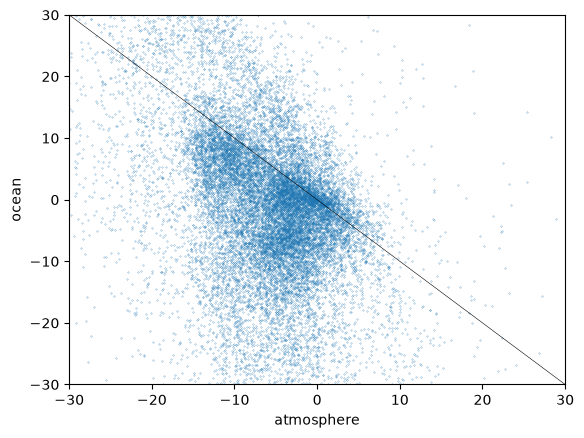

Python: Text(23.888888888888893, 0.5, 'ocean')

In [58]:
plot(f.adv_a[:], f.adv_o[:], marker=".", markersize=0.4, linestyle="none")
plot([-30, 30], [30, -30], "k", linewidth=0.4)
gca().set_ylim([-30, 30])
gca().set_xlim([-30, 30])
xlabel("atmosphere")
ylabel("ocean")

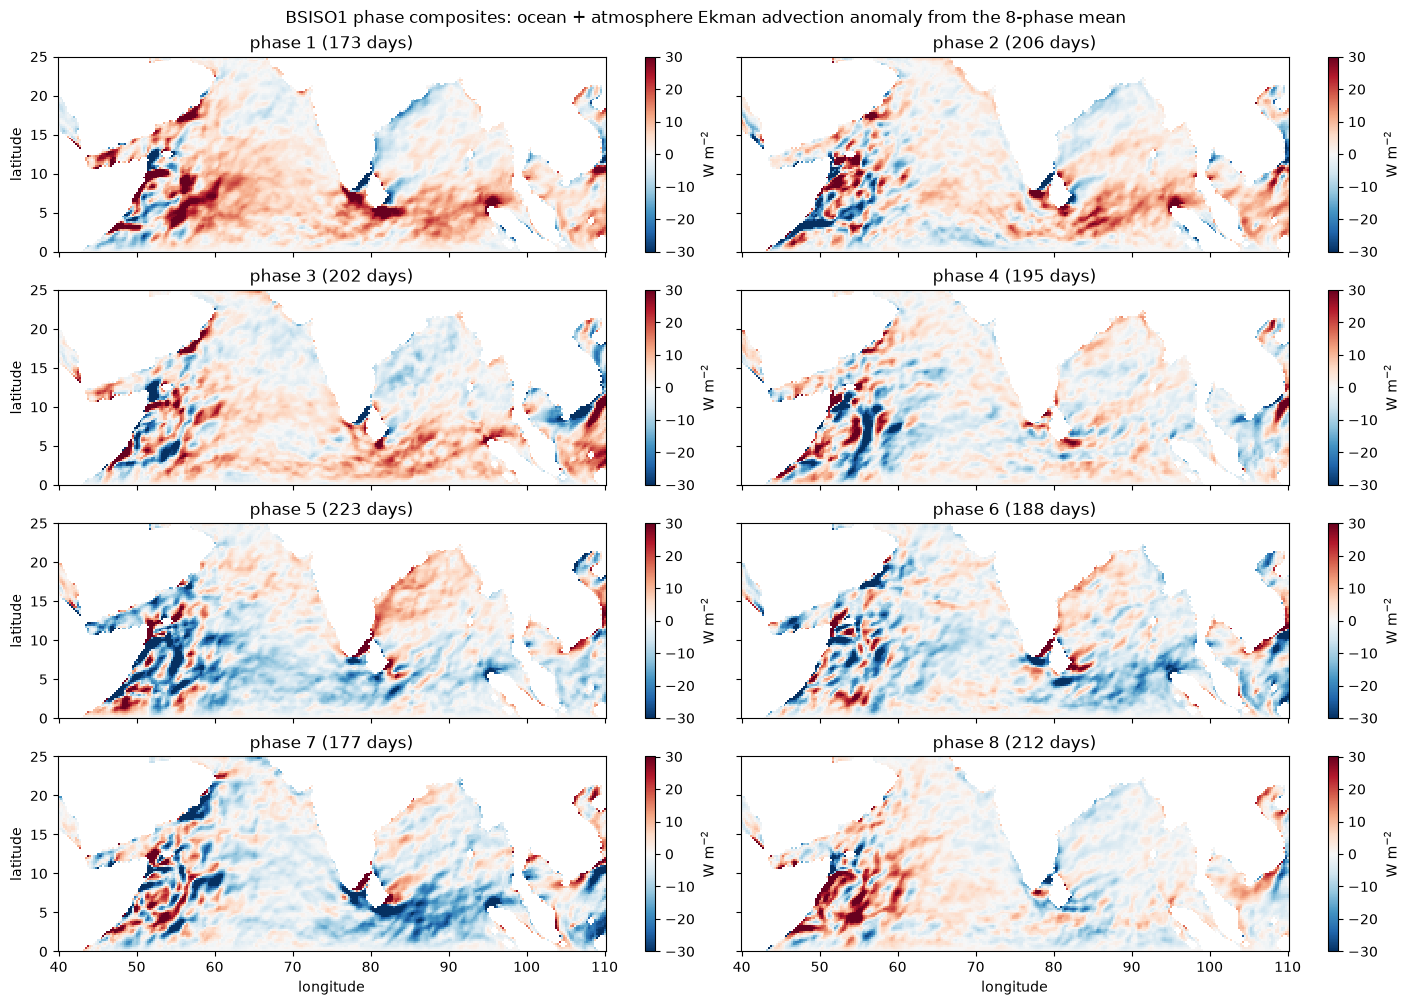

In [34]:
adv_tot_anom = anom(fp.adv_o .+ fp.adv_a; dims=3) # W m^-2, phase minus 8-phase mean
alim_adv = symlim(adv_tot_anom[.!land, :])        # over ocean, all phases
panels_adv_tot_anom = [panel(adv_tot_anom[:, :, q], daytitle(q), flux_units; vmin=-alim_adv, vmax=alim_adv) for q in 1:8]
fig_adv_tot_anom, axs_adv_tot_anom = plot_panels(lon, lat, panels_adv_tot_anom; ncols=2, land,
    suptitle="BSISO1 phase composites: ocean + atmosphere Ekman advection anomaly from the 8-phase mean");
for ax in axs_adv_tot_anom.flat
    ax.set_ylim(ylims...); # axes are shared: sets all panels
    ax.set_aspect("equal")
end
# fig_adv_tot_anom.savefig("bsiso_adv_tot_anom_phases.png")

Anomalous warming in advance of the monsoon, and cooling following it.